In [1]:
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


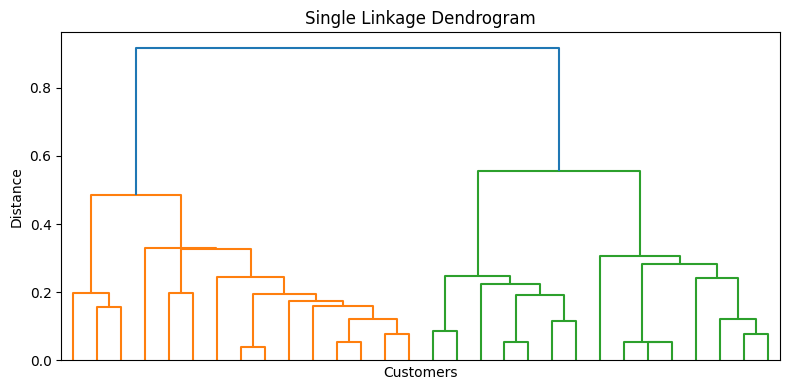

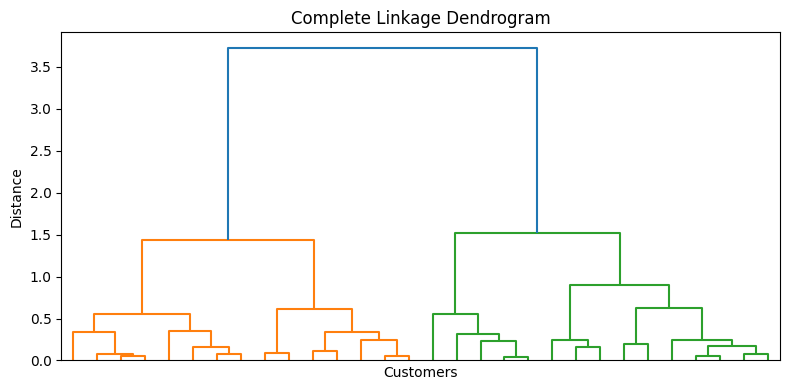

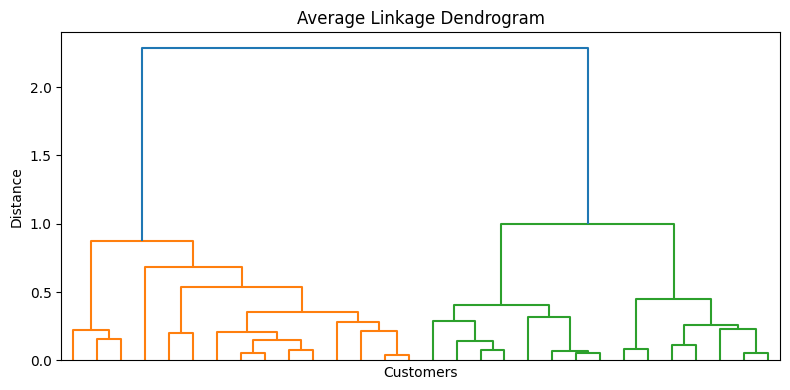

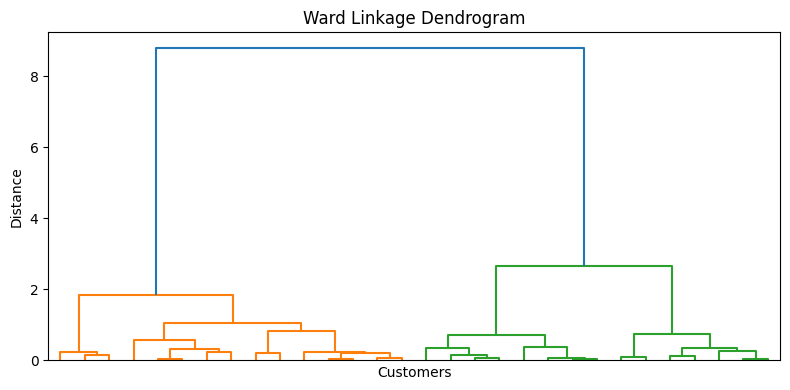


Cluster labels:
   Annual Income (k$)  Spending Score (1-100)  Cluster
0                  15                      39        4
1                  15                      81        3
2                  16                       6        4
3                  16                      77        3
4                  17                      40        4
5                  17                      76        3
6                  18                       6        4
7                  18                      94        3
8                  19                       3        4
9                  19                      72        3


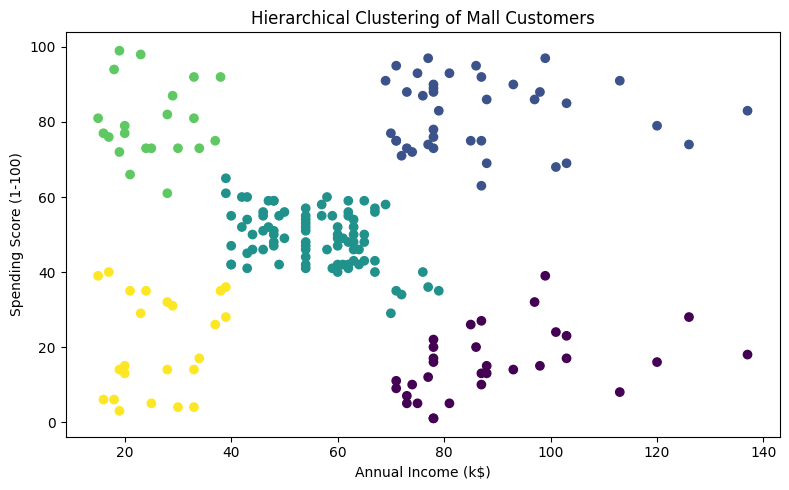

In [3]:
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.preprocessing import StandardScaler
from sklearn.cluster import AgglomerativeClustering
from scipy.cluster.hierarchy import dendrogram, linkage

# 1. Load dataset
df = pd.read_csv("/content/drive/MyDrive/ML_LAB/Mall.csv")

# 2. Select features
X = df[["Annual Income (k$)", "Spending Score (1-100)"]]

# 3. Scale features
scaler = StandardScaler()
X_scaled = scaler.fit_transform(X)

# 4. Use 30 customers for clear dendrograms
sample = X_scaled[:30]

methods = ["single", "complete", "average", "ward"]

for method in methods:
    Z = linkage(sample, method=method)

    plt.figure(figsize=(8, 4))
    dendrogram(Z, no_labels=True)
    plt.title(method.capitalize() + " Linkage Dendrogram")
    plt.xlabel("Customers")
    plt.ylabel("Distance")
    plt.tight_layout()
    plt.show()

# 5. Perform clustering on the full dataset
model = AgglomerativeClustering(n_clusters=5, linkage="ward")
df["Cluster"] = model.fit_predict(X_scaled)

# 6. Display cluster labels
print("\nCluster labels:")
print(df[["Annual Income (k$)",
          "Spending Score (1-100)",
          "Cluster"]].head(10))

# 7. Visualize clusters
plt.figure(figsize=(8, 5))

plt.scatter(
    X["Annual Income (k$)"],
    X["Spending Score (1-100)"],
    c=df["Cluster"],
    cmap="viridis"
)

plt.xlabel("Annual Income (k$)")
plt.ylabel("Spending Score (1-100)")
plt.title("Hierarchical Clustering of Mall Customers")
plt.tight_layout()
plt.show()